In [1]:
# NaaVRE step 1: Read input rows
# Purpose: Read the CSV file into a list of raw string records

import csv
from pathlib import Path

input_path = Path("C:/Users/alex/Downloads/NaaVRE-extension/NaaVRE-extension/naavre-ai-assistant/labs/plants/data/plant_growth.csv")

if not input_path.is_file():
    raise FileNotFoundError(f"Input file not found: {input_path}")

with input_path.open(mode="r", encoding="utf-8-sig", newline="") as f:
    reader = csv.DictReader(f)
    raw_records = list(reader)

print(f"Read {len(raw_records)} raw records from {input_path.name}")

Read 24 raw records from plant_growth.csv


In [2]:
# NaaVRE step 2: Validate schema
# Purpose: Verify that the CSV header row matches the expected schema labels

# Cell 2: Validate schema
# Verify that the CSV header row matches the expected schema labels

expected_headers = ["measurement_date", "plant_id", "treatment", "height_cm", "leaf_count", "biomass_g"]

# Extract actual headers from the first raw record (DictReader keys)
if raw_records:
    actual_headers = list(raw_records[0].keys())
else:
    actual_headers = []

# Check for missing expected columns
missing_columns = [col for col in expected_headers if col not in actual_headers]
# Check for unexpected extra columns
extra_columns = [col for col in actual_headers if col not in expected_headers]

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}. Found: {actual_headers}")

if extra_columns:
    print(f"Warning: Extra columns found (ignored): {extra_columns}")

schema_valid = True
print(f"Schema validation passed. Headers: {actual_headers}")

Schema validation passed. Headers: ['measurement_date', 'plant_id', 'treatment', 'height_cm', 'leaf_count', 'biomass_g']


In [3]:
# NaaVRE step 3: Parse data types
# Purpose: Convert raw string records into typed data structures and report parsing errors

# Cell 3: Parse data types
# Convert raw string records into typed data structures and report parsing errors

from datetime import date, datetime

parsed_records = []
parse_errors = []

for idx, raw in enumerate(raw_records, start=1):
    record = {}
    row_errors = []

    # Parse measurement_date (ISO timestamp)
    raw_date = raw.get("measurement_date", "").strip()
    if not raw_date:
        row_errors.append("measurement_date is empty")
    else:
        try:
            # Handle trailing Z for UTC
            date_str = raw_date
            if date_str.endswith("Z"):
                date_str = date_str[:-1] + "+00:00"
            dt_obj = datetime.fromisoformat(date_str)
            record["measurement_date"] = dt_obj
        except ValueError as e:
            row_errors.append(f"measurement_date '{raw_date}' is not a valid ISO timestamp: {e}")

    # Parse plant_id (text)
    raw_pid = raw.get("plant_id", "").strip()
    if not raw_pid:
        row_errors.append("plant_id is empty")
    else:
        record["plant_id"] = raw_pid

    # Parse treatment (text)
    raw_treat = raw.get("treatment", "").strip()
    if not raw_treat:
        row_errors.append("treatment is empty")
    else:
        record["treatment"] = raw_treat

    # Parse height_cm (float)
    raw_height = raw.get("height_cm", "").strip()
    if not raw_height:
        row_errors.append("height_cm is empty")
    else:
        try:
            record["height_cm"] = float(raw_height)
        except ValueError as e:
            row_errors.append(f"height_cm '{raw_height}' is not a valid number: {e}")

    # Parse leaf_count (int)
    raw_leaf = raw.get("leaf_count", "").strip()
    if not raw_leaf:
        row_errors.append("leaf_count is empty")
    else:
        try:
            record["leaf_count"] = int(raw_leaf)
        except ValueError as e:
            row_errors.append(f"leaf_count '{raw_leaf}' is not a valid integer: {e}")

    # Parse biomass_g (float)
    raw_biomass = raw.get("biomass_g", "").strip()
    if not raw_biomass:
        row_errors.append("biomass_g is empty")
    else:
        try:
            record["biomass_g"] = float(raw_biomass)
        except ValueError as e:
            row_errors.append(f"biomass_g '{raw_biomass}' is not a valid number: {e}")

    if row_errors:
        parse_errors.append({
            "row_index": idx,
            "raw_record": raw,
            "errors": row_errors
        })
    else:
        parsed_records.append(record)

print(f"Parsed {len(parsed_records)} valid records.")
if parse_errors:
    print(f"Found {len(parse_errors)} records with parsing errors:")
    for err in parse_errors:
        print(f"  Row {err['row_index']}: {'; '.join(err['errors'])}")
else:
    print("No parsing errors detected.")

Parsed 24 valid records.
No parsing errors detected.


In [4]:
# NaaVRE step 4: Calculate per-plant height change
# Purpose: Compute first and last height measurements and change per plant

# Cell 4: Calculate per-plant height change
# Group by plant_id, sort by measurement_date, compute first/last valid height and change

from collections import defaultdict

# Group parsed records by plant_id
plants = defaultdict(list)
for rec in parsed_records:
    plants[rec["plant_id"]].append(rec)

plant_changes = []
excluded_plants = []

for plant_id in sorted(plants.keys()):
    records = plants[plant_id]
    # Sort by measurement_date
    records.sort(key=lambda r: r["measurement_date"])
    
    # Filter to records with valid height_cm
    valid_heights = [r for r in records if "height_cm" in r and r["height_cm"] is not None]
    
    if len(valid_heights) < 2:
        excluded_plants.append({
            "plant_id": plant_id,
            "treatment": records[0]["treatment"] if records else "unknown",
            "n_measurements": len(records),
            "n_valid_heights": len(valid_heights),
            "reason": "Fewer than 2 valid height measurements"
        })
        continue
    
    first = valid_heights[0]
    last = valid_heights[-1]
    change_cm = last["height_cm"] - first["height_cm"]
    
    plant_changes.append({
        "plant_id": plant_id,
        "treatment": first["treatment"],
        "first_date": first["measurement_date"],
        "first_height_cm": first["height_cm"],
        "last_date": last["measurement_date"],
        "last_height_cm": last["height_cm"],
        "change_cm": change_cm,
        "n_measurements": len(records),
        "n_valid_heights": len(valid_heights)
    })

print(f"Computed height change for {len(plant_changes)} plants.")
if excluded_plants:
    print(f"Excluded {len(excluded_plants)} plants due to insufficient valid measurements:")
    for ex in excluded_plants:
        print(f"  {ex['plant_id']} ({ex['treatment']}): {ex['n_valid_heights']} valid height(s), {ex['reason']}")
else:
    print("No plants excluded.")

print("\nPer-plant height change summary:")
print(f"{'plant_id':<10} {'treatment':<12} {'first_date':<12} {'first_cm':<10} {'last_date':<12} {'last_cm':<10} {'change_cm':<10} {'n_meas':<6}")
for pc in plant_changes:
    print(f"{pc['plant_id']:<10} {pc['treatment']:<12} {pc['first_date'].strftime('%Y-%m-%d'):<12} {pc['first_height_cm']:<10.1f} {pc['last_date'].strftime('%Y-%m-%d'):<12} {pc['last_height_cm']:<10.1f} {pc['change_cm']:<10.1f} {pc['n_measurements']:<6}")

Computed height change for 6 plants.
No plants excluded.

Per-plant height change summary:
plant_id   treatment    first_date   first_cm   last_date    last_cm    change_cm  n_meas
P01        control      2026-03-01   8.2        2026-03-22   13.8       5.6        4     
P02        control      2026-03-01   8.5        2026-03-22   14.1       5.6        4     
P03        control      2026-03-01   7.9        2026-03-22   13.5       5.6        4     
P04        fertilized   2026-03-01   8.4        2026-03-22   18.3       9.9        4     
P05        fertilized   2026-03-01   8.1        2026-03-22   17.8       9.7        4     
P06        fertilized   2026-03-01   8.6        2026-03-22   18.7       10.1       4     


In [5]:
# NaaVRE step 5: Summarize treatment groups over time
# Purpose: Aggregate height statistics by treatment and date

# Cell 5: Summarize treatment groups over time
# Aggregate height statistics by treatment and date

from collections import defaultdict
import statistics

# Group parsed records by (treatment, measurement_date)
treatment_date_groups = defaultdict(list)
for rec in parsed_records:
    if "height_cm" in rec and rec["height_cm"] is not None:
        key = (rec["treatment"], rec["measurement_date"])
        treatment_date_groups[key].append(rec)

# Build summary: list of dicts, one per (treatment, date)
treatment_summary = []

for (treatment, dt) in sorted(treatment_date_groups.keys(), key=lambda x: (x[1], x[0])):
    records = treatment_date_groups[(treatment, dt)]
    heights = [r["height_cm"] for r in records]
    n_plants = len(heights)
    
    mean_h = statistics.mean(heights)
    min_h = min(heights)
    max_h = max(heights)
    
    # Median: use statistics.median (works for any count >= 1)
    median_h = statistics.median(heights)
    
    treatment_summary.append({
        "treatment": treatment,
        "date": dt,
        "n_plants": n_plants,
        "mean_height_cm": round(mean_h, 4),
        "median_height_cm": round(median_h, 4),
        "min_height_cm": round(min_h, 4),
        "max_height_cm": round(max_h, 4)
    })

# Also compute overall per-treatment mean change from plant_changes (Cell 4)
treatment_change_summary = defaultdict(list)
for pc in plant_changes:
    treatment_change_summary[pc["treatment"]].append(pc["change_cm"])

print("Treatment-level summary by date (height in cm):")
print(f"{'treatment':<12} {'date':<12} {'n':<5} {'mean':<10} {'median':<10} {'min':<10} {'max':<10}")
for ts in treatment_summary:
    print(f"{ts['treatment']:<12} {ts['date'].strftime('%Y-%m-%d'):<12} {ts['n_plants']:<5} {ts['mean_height_cm']:<10.2f} {ts['median_height_cm']:<10.2f} {ts['min_height_cm']:<10.2f} {ts['max_height_cm']:<10.2f}")

print("\nPer-treatment mean height change (cm):")
for treat in sorted(treatment_change_summary.keys()):
    changes = treatment_change_summary[treat]
    if changes:
        mean_change = statistics.mean(changes)
        print(f"  {treat}: mean change = {mean_change:.2f} cm (n={len(changes)} plants)")

print("\nNote: Repeated rows from the same plant are not independent replicates. Descriptive statistics only.")

Treatment-level summary by date (height in cm):
treatment    date         n     mean       median     min        max       
control      2026-03-01   3     8.20       8.20       7.90       8.50      
fertilized   2026-03-01   3     8.37       8.40       8.10       8.60      
control      2026-03-08   3     10.10      10.10      9.80       10.40     
fertilized   2026-03-08   3     11.20      11.20      10.90      11.50     
control      2026-03-15   3     11.97      12.00      11.70      12.20     
fertilized   2026-03-15   3     14.67      14.70      14.30      15.00     
control      2026-03-22   3     13.80      13.80      13.50      14.10     
fertilized   2026-03-22   3     18.27      18.30      17.80      18.70     

Per-treatment mean height change (cm):
  control: mean change = 5.60 cm (n=3 plants)
  fertilized: mean change = 9.90 cm (n=3 plants)

Note: Repeated rows from the same plant are not independent replicates. Descriptive statistics only.


SVG chart saved to: outputs\height_by_treatment.svg (6430 bytes)


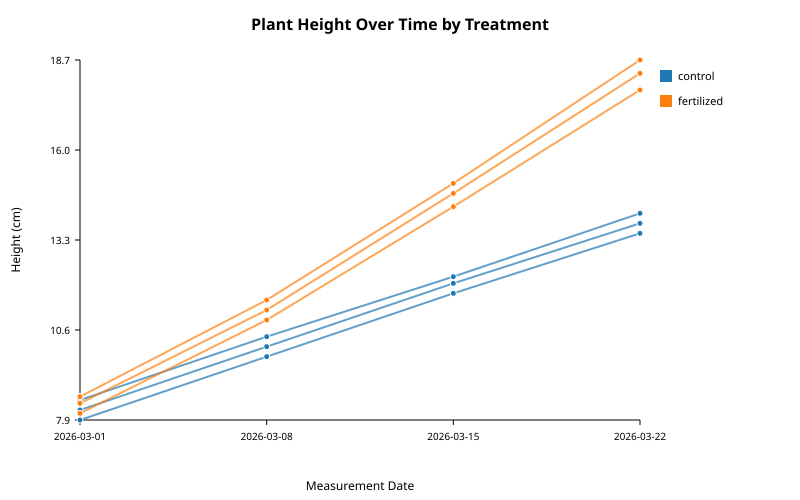

In [6]:
# NaaVRE step 6: Generate height trend chart
# Purpose: Create and display an SVG line chart of height over time by treatment

# Cell 6: Generate height trend chart
# Create and display an SVG line chart of height over time by treatment

import xml.etree.ElementTree as ET
from pathlib import Path
from collections import defaultdict

# --- Prepare data for plotting ---
# Group parsed_records by treatment, then by plant_id, sorted by date
treatment_plants = defaultdict(lambda: defaultdict(list))
for rec in parsed_records:
    if "height_cm" in rec and rec["height_cm"] is not None:
        treatment_plants[rec["treatment"]][rec["plant_id"]].append(rec)

# Sort each plant's records by date
for treat in treatment_plants:
    for pid in treatment_plants[treat]:
        treatment_plants[treat][pid].sort(key=lambda r: r["measurement_date"])

# Collect all unique dates and heights for axis scaling
all_dates = set()
all_heights = []
for treat in treatment_plants:
    for pid in treatment_plants[treat]:
        for rec in treatment_plants[treat][pid]:
            all_dates.add(rec["measurement_date"])
            all_heights.append(rec["height_cm"])

if not all_dates or not all_heights:
    raise ValueError("No valid data points to plot.")

min_date = min(all_dates)
max_date = max(all_dates)
min_h = min(all_heights)
max_h = max(all_heights)

# Handle single date or constant height
if min_date == max_date:
    date_span = 1.0
    date_mid = min_date
else:
    date_span = (max_date - min_date).total_seconds()
    date_mid = None

if min_h == max_h:
    h_span = 1.0
    h_mid = min_h
else:
    h_span = max_h - min_h
    h_mid = None

# --- SVG dimensions ---
svg_width = 800
svg_height = 500
margin_left = 80
margin_right = 160
margin_top = 60
margin_bottom = 80
plot_width = svg_width - margin_left - margin_right
plot_height = svg_height - margin_top - margin_bottom

# --- Coordinate mapping ---
def date_to_x(dt):
    if date_span == 0:
        return margin_left + plot_width / 2
    frac = (dt - min_date).total_seconds() / date_span
    return margin_left + frac * plot_width

def height_to_y(h):
    if h_span == 0:
        return margin_top + plot_height / 2
    frac = (h - min_h) / h_span
    return margin_top + plot_height - frac * plot_height

# --- Build SVG ---
svg = ET.Element("svg", {
    "xmlns": "http://www.w3.org/2000/svg",
    "width": str(svg_width),
    "height": str(svg_height),
    "viewBox": f"0 0 {svg_width} {svg_height}"
})

# Background
ET.SubElement(svg, "rect", {
    "width": str(svg_width),
    "height": str(svg_height),
    "fill": "white"
})

# Title
title_el = ET.SubElement(svg, "text", {
    "x": str(svg_width // 2),
    "y": "30",
    "text-anchor": "middle",
    "font-size": "16",
    "font-family": "sans-serif",
    "font-weight": "bold"
})
title_el.text = "Plant Height Over Time by Treatment"

# Axis labels
x_label = ET.SubElement(svg, "text", {
    "x": str(margin_left + plot_width // 2),
    "y": str(svg_height - 10),
    "text-anchor": "middle",
    "font-size": "12",
    "font-family": "sans-serif"
})
x_label.text = "Measurement Date"

y_label = ET.SubElement(svg, "text", {
    "x": "20",
    "y": str(margin_top + plot_height // 2),
    "text-anchor": "middle",
    "font-size": "12",
    "font-family": "sans-serif",
    "transform": f"rotate(-90, 20, {margin_top + plot_height // 2})"
})
y_label.text = "Height (cm)"

# Axis lines
ET.SubElement(svg, "line", {
    "x1": str(margin_left), "y1": str(margin_top + plot_height),
    "x2": str(margin_left + plot_width), "y2": str(margin_top + plot_height),
    "stroke": "black", "stroke-width": "1"
})
ET.SubElement(svg, "line", {
    "x1": str(margin_left), "y1": str(margin_top),
    "x2": str(margin_left), "y2": str(margin_top + plot_height),
    "stroke": "black", "stroke-width": "1"
})

# X-axis ticks (up to 5)
n_ticks = min(5, len(all_dates))
if n_ticks > 0:
    sorted_dates = sorted(all_dates)
    if len(sorted_dates) == 1:
        tick_dates = [sorted_dates[0]]
    else:
        step = max(1, len(sorted_dates) // (n_ticks - 1))
        tick_dates = sorted_dates[::step]
        if tick_dates[-1] != sorted_dates[-1]:
            tick_dates.append(sorted_dates[-1])
    
    for dt in tick_dates:
        x = date_to_x(dt)
        ET.SubElement(svg, "line", {
            "x1": str(x), "y1": str(margin_top + plot_height),
            "x2": str(x), "y2": str(margin_top + plot_height + 5),
            "stroke": "black", "stroke-width": "1"
        })
        tick_label = ET.SubElement(svg, "text", {
            "x": str(x),
            "y": str(margin_top + plot_height + 20),
            "text-anchor": "middle",
            "font-size": "10",
            "font-family": "sans-serif"
        })
        tick_label.text = dt.strftime("%Y-%m-%d")

# Y-axis ticks (5 ticks)
n_y_ticks = 5
for i in range(n_y_ticks):
    h_val = min_h + (h_span * i / (n_y_ticks - 1)) if h_span > 0 else min_h
    y = height_to_y(h_val)
    ET.SubElement(svg, "line", {
        "x1": str(margin_left - 5), "y1": str(y),
        "x2": str(margin_left), "y2": str(y),
        "stroke": "black", "stroke-width": "1"
    })
    tick_label = ET.SubElement(svg, "text", {
        "x": str(margin_left - 10),
        "y": str(y + 4),
        "text-anchor": "end",
        "font-size": "10",
        "font-family": "sans-serif"
    })
    tick_label.text = f"{h_val:.1f}"

# --- Plot lines and points per treatment ---
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
treatments = sorted(treatment_plants.keys())

for t_idx, treat in enumerate(treatments):
    color = colors[t_idx % len(colors)]
    plants = treatment_plants[treat]
    
    # Draw line connecting plant means? No — draw individual plant lines
    for pid in sorted(plants.keys()):
        records = plants[pid]
        if len(records) < 2:
            # Single point
            rec = records[0]
            x = date_to_x(rec["measurement_date"])
            y = height_to_y(rec["height_cm"])
            ET.SubElement(svg, "circle", {
                "cx": str(x), "cy": str(y), "r": "4",
                "fill": color, "stroke": "white", "stroke-width": "1"
            })
        else:
            # Draw line
            points = []
            for rec in records:
                x = date_to_x(rec["measurement_date"])
                y = height_to_y(rec["height_cm"])
                points.append(f"{x},{y}")
            
            if len(points) >= 2:
                polyline = ET.SubElement(svg, "polyline", {
                    "points": " ".join(points),
                    "fill": "none",
                    "stroke": color,
                    "stroke-width": "2",
                    "opacity": "0.7"
                })
            
            # Draw points
            for rec in records:
                x = date_to_x(rec["measurement_date"])
                y = height_to_y(rec["height_cm"])
                ET.SubElement(svg, "circle", {
                    "cx": str(x), "cy": str(y), "r": "3",
                    "fill": color, "stroke": "white", "stroke-width": "1"
                })

# --- Legend ---
legend_x = margin_left + plot_width + 20
legend_y = margin_top + 10
for t_idx, treat in enumerate(treatments):
    color = colors[t_idx % len(colors)]
    ly = legend_y + t_idx * 25
    ET.SubElement(svg, "rect", {
        "x": str(legend_x), "y": str(ly),
        "width": "12", "height": "12",
        "fill": color
    })
    legend_text = ET.SubElement(svg, "text", {
        "x": str(legend_x + 18),
        "y": str(ly + 10),
        "font-size": "11",
        "font-family": "sans-serif"
    })
    legend_text.text = treat

# --- Write SVG to file ---
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "height_by_treatment.svg"

tree = ET.ElementTree(svg)
ET.indent(tree, space="  ")
tree.write(str(output_path), encoding="unicode", xml_declaration=True)

# Verify output
if not output_path.is_file():
    raise IOError(f"Failed to write SVG to {output_path}")

file_size = output_path.stat().st_size
if file_size == 0:
    raise IOError(f"SVG file is empty: {output_path}")

print(f"SVG chart saved to: {output_path} ({file_size} bytes)")

# --- Display inline if IPython is available ---
try:
    from IPython.display import SVG, display
    with open(output_path, "r", encoding="utf-8") as f:
        svg_content = f.read()
    display(SVG(svg_content))
except ImportError:
    print(f"IPython not available. View the chart at: {output_path}")